# Complete motor-cortex spectral hemoglobin inversion

This notebook actively reconstructs all 136 native intensity channels and all 4860 samples of FRESH subject 01, left2s. It compares freshly executed local mathematics with an independently executed MNE-Python1.12.1 reference. No physiological truth is available. The recording is CC0 by Rickson C. Mesquita (doi:10.18112/openneuro.ds005963.v1.0.0); source revision, original environment and exact hashes are in `test/validation.md`.

Near-infrared attenuation depends on overlapping hemoglobin absorption spectra. Continuous-wave measurements do not determine absolute concentration or tissue depth. The unknown here is the **effective relative** HbO/HbR concentration at each measured source–detector path, including short-separation paths.

## Physics, gauge and closed-form method

For pair $p$, wavelength $w$, chromophore $j$ and sample $t$, define $z=-\ln(I/\bar I)$ using the arithmetic temporal mean $\bar I$ of each channel. The forward model is $z_{pwt}=\sum_j A_{pwj}c_{pjt}$, with $A_{pwj}=1000 E_{wj}d_p f_w$. Here $I$ is instrument intensity, $E$ is natural-log absorption in m^-1 mM^-1, $d$ is source–detector separation in meters, $f_w=6$ is dimensionless partial pathlength, and $c$ is mol/L. Species order is HbO then HbR. Two-wavelength spectral overlap determines matrix conditioning.

At each path/time, minimize $\frac12\|Ac-z\|_2^2$. For $A=\left[\begin{smallmatrix}a&b\\g&h\end{smallmatrix}\right]$ and $D=ah-bg$, evaluate $c_0=(hz_0-bz_1)/D$, $c_1=(-gz_0+az_1)/D$. There is no iteration, smoothing or positivity constraint. Concentrations may be negative and their temporal means need not vanish under this intensity-baseline convention. Code evaluates these equations locally with float64 NumPy operations.

The full square system fits OD essentially exactly. This residual checks algebra/units, **not physiological correctness**. Pathlength and superficial-tissue assumptions remain unverified.

In [1]:
from pathlib import Path
import os,sys,json,time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.main import run
from src.visualization import experiments,figures,metrics
obs=load_observations(ROOT/'data/raw_data.npz')
start=time.perf_counter()
fresh,cli_runtime=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz')
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as z: original=z['reconstruction']
results=experiments(obs,original)
assert np.array_equal(fresh,results['fresh'])
results['measurements']['canonical_runtime_seconds']=cli_runtime
results['measurements']['all_experiments_runtime_seconds']=time.perf_counter()-start
print(json.dumps(results['measurements'],indent=2))
(ROOT/'notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(results['measurements'],indent=2,allow_nan=False),encoding='utf-8')
plots=figures(obs,results)
plt.close('all')

{
  "hbo_ncc": 1.0000000000000029,
  "hbo_nrmse": 8.725454284175138e-18,
  "hbr_ncc": 1.0000000000000002,
  "hbr_nrmse": 1.4751889331396248e-17,
  "forward_relative_rms": 1.5687220066700879e-16,
  "max_absolute_upstream_difference": 3.3881317890172014e-21,
  "matrix_condition_number": 3.206208353438045,
  "short_channels": 4,
  "single_wavelength_relative_error": 0.8861644380317752,
  "short_regression_relative_change": 0.4401179361201338,
  "ppf_relative_changes": [
    0.25,
    0.11111111111111119,
    0.0,
    0.09090909090909098,
    0.16666666666666718
  ],
  "decimation_relative_changes": [
    0.0,
    0.004185771041578919,
    0.0071996870348448915,
    0.011167625975389943,
    0.012895342199124644
  ],
  "regularized_relative_changes": [
    0.004759209958864838,
    0.0453132186203922,
    0.3066899667493694,
    0.7436887060496357
  ],
  "canonical_runtime_seconds": 0.15605049999430776,
  "all_experiments_runtime_seconds": 0.3491577999666333
}


## Full observations and reconstructed signed concentration

The first plate displays every sample and pair. Concentration maps share a symmetric signed color range covering all values; no percentile clipping or display denoising is applied. Pair 0 illustrates how multiplicative raw-channel scales disappear in optical density.

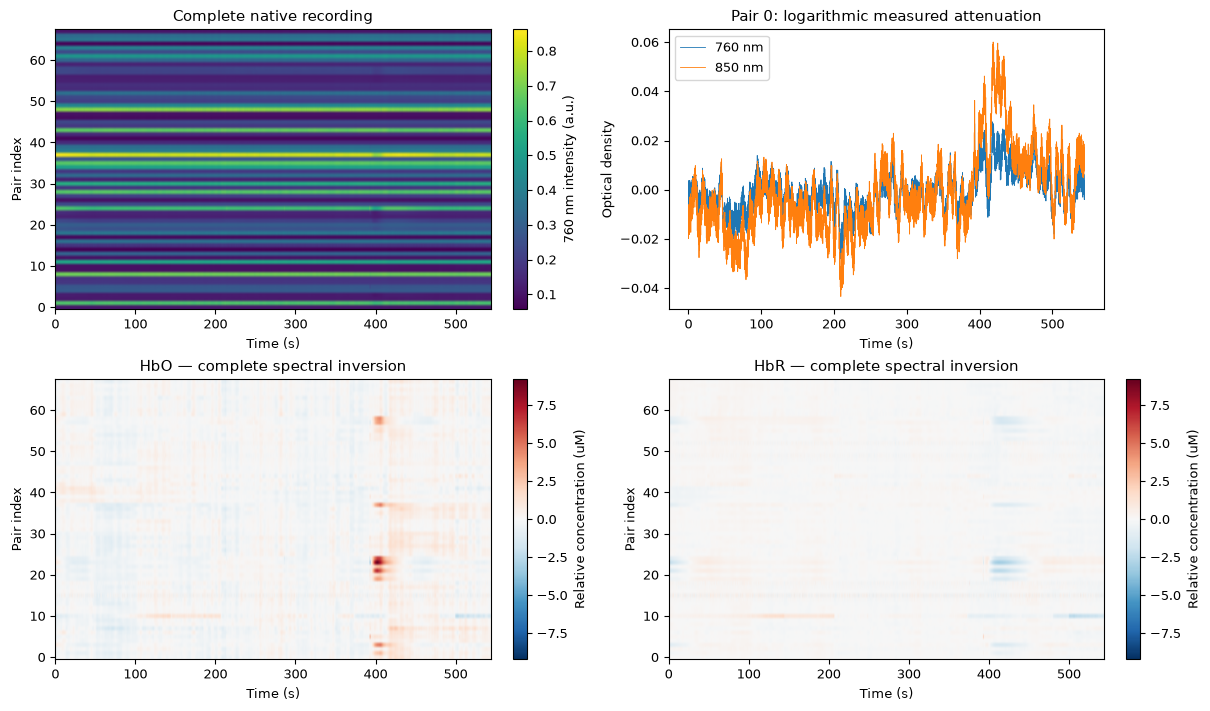

In [2]:
display(plots['recording']); plt.close(plots['recording'])

## Independent original comparison and wavelength identifiability

Dashed original traces are archived original MNE measurements, while solid fresh traces were computed above from local modules. The histogram uses every concentration element. The single-wavelength minimum-norm comparison is computed from the actual 760-nm OD: c=a^T z/(a a^T). It has insufficient spectral information to determine both species. A small residual therefore cannot establish correct species separation.

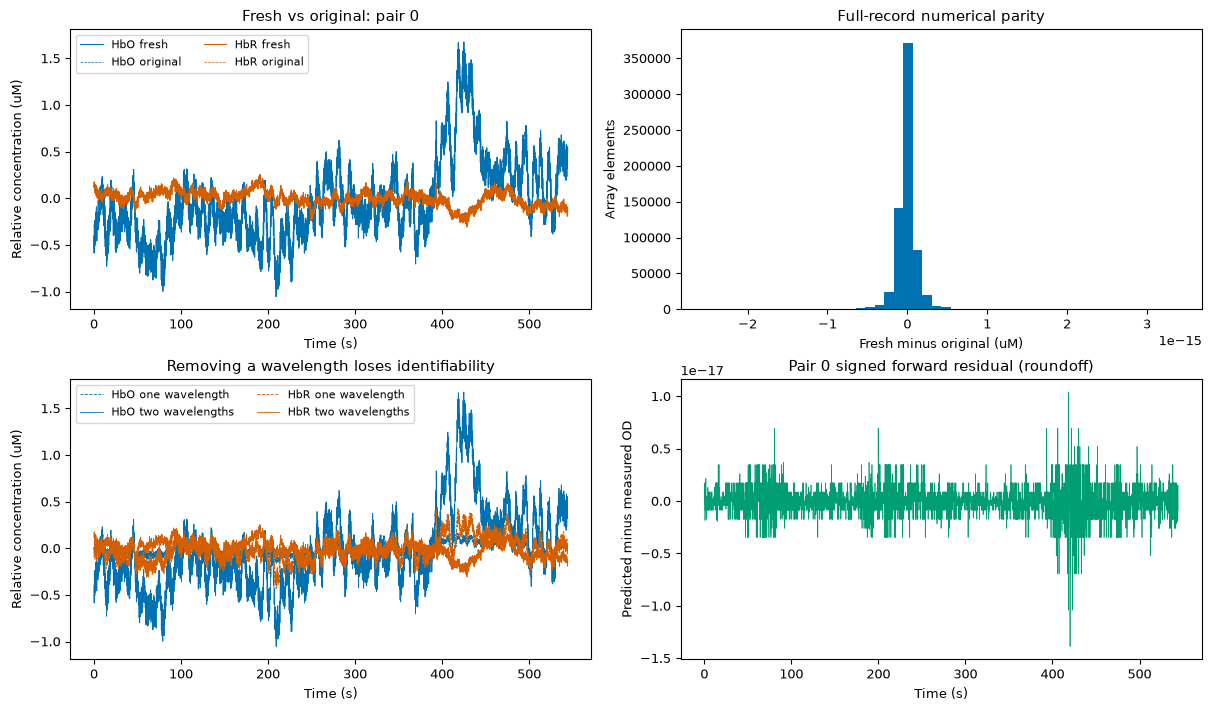

In [3]:
display(plots['parity_identifiability']); plt.close(plots['parity_identifiability'])

## Controlled acquisition and calibration sensitivity

All five pathlength choices and all five temporal sampling choices are freshly reconstructed. Decimation retains original samples without interpolation; it changes the arithmetic mean used as baseline and can alias physiology. Error is evaluated only at the retained native samples. Midpoint maps show RMS fluctuations over the full recording, projected into original head x/y coordinates; these are sensor-path summaries, not depth-resolved cortical maps. Identical nonnegative color ranges permit HbO/HbR comparison.

Additional fresh experiments quantify ridge regularization and regression against the mean short-separation channel signal. Ridge solves (A^T A + lambda I)c=A^Tz with lambda equal to a declared fraction of trace(A^TA)/2. Short regression subtracts the least-squares projection onto the centered mean of channels with separation below15mm, separately for each chromophore. These comparisons alter the scientific estimator and do not become the benchmark reference.

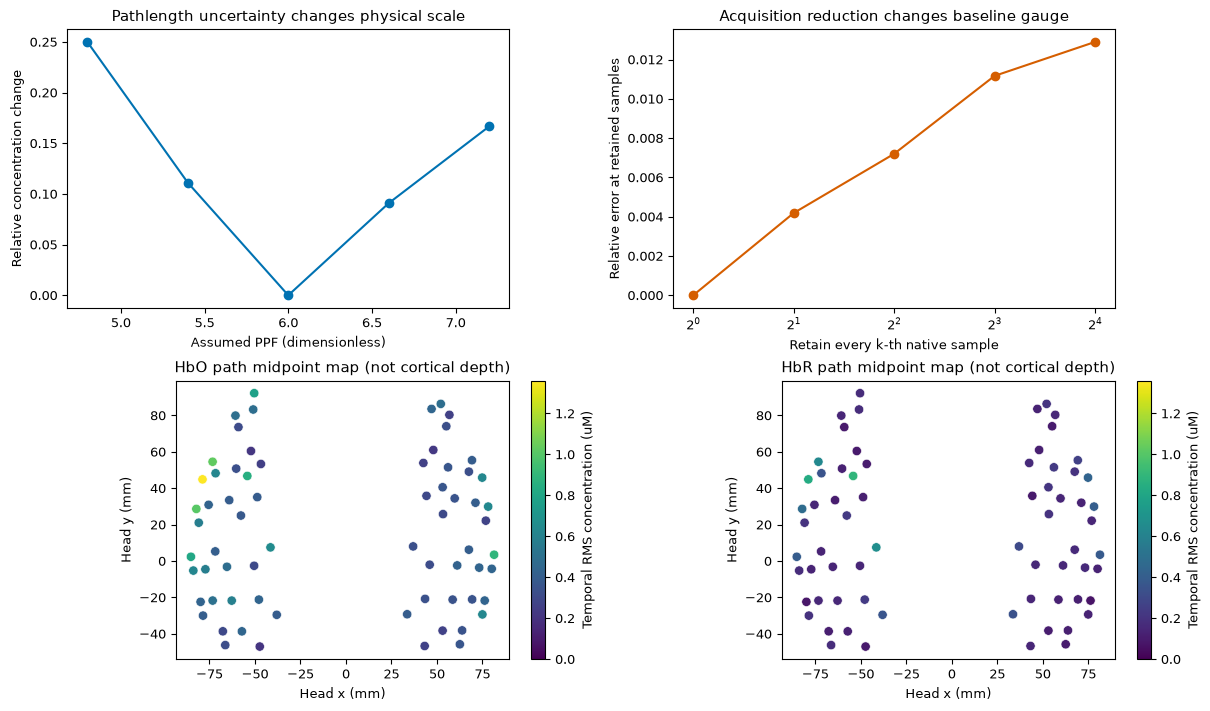

In [4]:
display(plots['sensitivity_channel_maps']); plt.close(plots['sensitivity_channel_maps'])

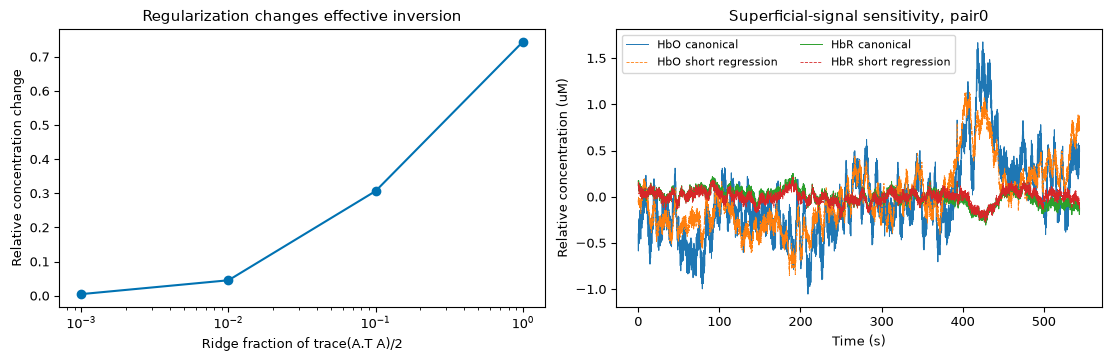

In [5]:
fig,ax=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
ax[0].semilogx([.001,.01,.1,1.],results['measurements']['regularized_relative_changes'],'o-',color='#0072B2')
ax[0].set(xlabel='Ridge fraction of trace(A.T A)/2',ylabel='Relative concentration change',title='Regularization changes effective inversion')
time=np.arange(4860)/8.928571428571429
for j,name in enumerate(('HbO','HbR')):
 ax[1].plot(time,results['fresh'][0,0,j]*1e6,lw=.7,label=name+' canonical')
 ax[1].plot(time,results['corrected'][0,0,j]*1e6,lw=.6,ls='--',label=name+' short regression')
ax[1].set(xlabel='Time (s)',ylabel='Relative concentration (uM)',title='Superficial-signal sensitivity, pair0');ax[1].legend(fontsize=8,ncol=2)
plots['regularization_short_regression']=fig
plt.close(fig)
display(fig);plt.close(fig)

In [6]:
import importlib.util
spec=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz')
assert report['status']=='pass',report
print(json.dumps(report,indent=2))
# Numerical metric definitions are checked against an independent known case.
y=np.array([0.,1.,2.]); assert abs(judge.component_metrics(y,y)['ncc']-1)<1e-15
assert judge.component_metrics(y,y)['nrmse']==0
print('All native concentrations finite:',bool(np.isfinite(fresh).all()))

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "hbo_ncc": 1.0000000000000029,
    "hbo_nrmse": 8.725454284175138e-18,
    "hbr_ncc": 1.0000000000000002,
    "hbr_nrmse": 1.4751889331396248e-17,
    "forward_relative_rms": 1.8509418462827703e-16
  },
  "thresholds": {
    "hbo_ncc": {
      "comparison": ">=",
      "boundary": 0.999999999
    },
    "hbo_nrmse": {
      "comparison": "<=",
      "boundary": 1e-09
    },
    "hbr_ncc": {
      "comparison": ">=",
      "boundary": 0.999999999
    },
    "hbr_nrmse": {
      "comparison": "<=",
      "boundary": 1e-09
    },
    "forward_relative_rms": {
      "comparison": "<=",
      "boundary": 1e-10
    }
  },
  "errors": []
}
All native concentrations finite: True


## Conclusion and limitations

The full native recording reconstructs successfully, agrees with the independently executed original algorithm at float64 roundoff, and satisfies the declared forward model. Both chromophores and all paths are retained. This validates a local numerical implementation, not absolute cerebral concentration. Assumed pathlength changes scale, one wavelength cannot identify two species, short paths include superficial physiology, and decimation changes the baseline gauge. No true hemoglobin ground truth, calibrated noise variance or absolute pathlength is available; no claim about physiological accuracy or cortical depth is made.